In [40]:

import pandas as pd

df = pd.read_csv("diabetes_health_indicators.csv")

print("Dataset berhasil dibaca!")
print("Ukuran dataset:", df.shape)
print(df.head())


Dataset berhasil dibaca!
Ukuran dataset: (229474, 22)
   HighBP  HighChol  CholCheck  BMI  Smoker  Stroke  HeartDiseaseorAttack  \
0       1         1          1   40       1       0                     0   
1       0         0          0   25       1       0                     0   
2       1         1          1   28       0       0                     0   
3       1         0          1   27       0       0                     0   
4       1         1          1   24       0       0                     0   

   PhysActivity  Fruits  Veggies  ...  NoDocbcCost  GenHlth  MentHlth  \
0             0       0        1  ...            0        5        18   
1             1       0        0  ...            1        3         0   
2             0       1        0  ...            1        5        30   
3             1       1        1  ...            0        2         0   
4             1       1        1  ...            0        2         3   

   PhysHlth  DiffWalk  Sex  Age  Education  

In [49]:

import pandas as pd
import numpy as np

# 1. Memuat dataset
df = pd.read_csv("diabetes_health_indicators.csv")

# 2. Menampilkan ukuran dataset awal
print("Ukuran dataset awal:", df.shape)

# 3. Memeriksa informasi dataset
print("\nInformasi dataset:")
df.info()

# 4. Memeriksa data kosong
print("\nJumlah data kosong setiap kolom:")
print(df.isnull().sum())

# 5. Memeriksa jumlah data duplikat
print("\nJumlah data duplikat:", df.duplicated().sum())

# 6. Memeriksa nilai tak hingga
print("\nJumlah nilai tak hingga:")
print(np.isinf(df.select_dtypes(include="number")).sum().sum())

# 7. Menghapus data duplikat
df_clean = df.drop_duplicates().copy()

# 8. Memeriksa kembali data kosong
print("\nJumlah data kosong setelah pembersihan:")
print(df_clean.isnull().sum().sum())

# 9. Memeriksa kembali data duplikat
print("Jumlah duplikat setelah pembersihan:", df_clean.duplicated().sum())

# 10. Menampilkan ukuran dataset setelah pembersihan
print("\nUkuran dataset setelah pembersihan:", df_clean.shape)

# 11. Menyimpan dataset yang sudah dibersihkan
df_clean.to_csv("diabetes_health_indicators_clean.csv", index=False)

print("\nDataset bersih berhasil disimpan.")


Ukuran dataset awal: (229474, 22)

Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 229474 entries, 0 to 229473
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype
---  ------                --------------   -----
 0   HighBP                229474 non-null  int64
 1   HighChol              229474 non-null  int64
 2   CholCheck             229474 non-null  int64
 3   BMI                   229474 non-null  int64
 4   Smoker                229474 non-null  int64
 5   Stroke                229474 non-null  int64
 6   HeartDiseaseorAttack  229474 non-null  int64
 7   PhysActivity          229474 non-null  int64
 8   Fruits                229474 non-null  int64
 9   Veggies               229474 non-null  int64
 10  HvyAlcoholConsump     229474 non-null  int64
 11  AnyHealthcare         229474 non-null  int64
 12  NoDocbcCost           229474 non-null  int64
 13  GenHlth               229474 non-null  int64
 14  MentHlth              229474 non-null  in

In [50]:

from sklearn.model_selection import train_test_split

# Memisahkan fitur dan target
X = df.drop(columns=["Diabetes_binary"])
y = df["Diabetes_binary"]

# Membagi data latih dan data uji
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

print("Data latih:", X_train.shape)
print("Data uji:", X_test.shape)


Data latih: (160631, 21)
Data uji: (68843, 21)


In [51]:
#Normalisasi Data
from sklearn import preprocessing

X_train_norm = preprocessing.normalize(X_train)
X_test_norm = preprocessing.normalize(X_test)

print(X_train_norm.shape)
print(X_test_norm.shape)


(160631, 21)
(68843, 21)


In [52]:

from xgboost import XGBClassifier

xgboost_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    eval_metric="logloss"
)

model_fit = xgboost_model.fit(X_train, y_train)


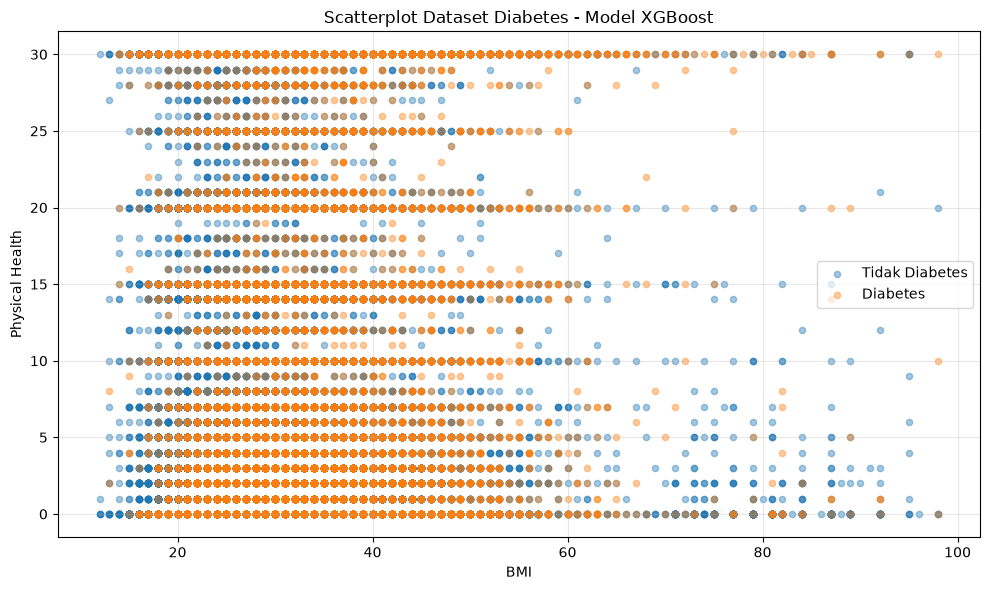

In [53]:
#Menampilkan scatterplot
import matplotlib.pyplot as plt

# Membuat scatterplot dari dataset diabetes
plt.figure(figsize=(10, 6))

for kelas, label in [(0, "Tidak Diabetes"), (1, "Diabetes")]:
    data = df[df["Diabetes_binary"] == kelas]

    plt.scatter(
        data["BMI"],
        data["PhysHlth"],
        label=label,
        alpha=0.4,
        s=20
    )

plt.title("Scatterplot Dataset Diabetes - Model XGBoost")
plt.xlabel("BMI")
plt.ylabel("Physical Health")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Menyimpan gambar
plt.savefig("scatterplot_diabetes_xgboost.png", dpi=300)
plt.show()


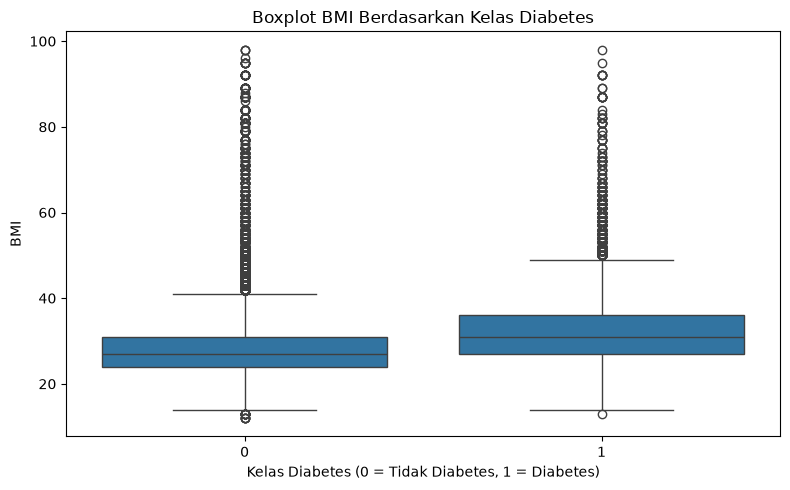

In [54]:
#Menampilkan Boxplot
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
sns.boxplot(x=y_train, y=X_train["BMI"])

plt.title("Boxplot BMI Berdasarkan Kelas Diabetes")
plt.xlabel("Kelas Diabetes (0 = Tidak Diabetes, 1 = Diabetes)")
plt.ylabel("BMI")
plt.tight_layout()
plt.show()

In [55]:
from sklearn.metrics import accuracy_score

y_pred = model_xgb.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Akurasi XGBoost:", accuracy)

Akurasi XGBoost: 0.8528971718257484


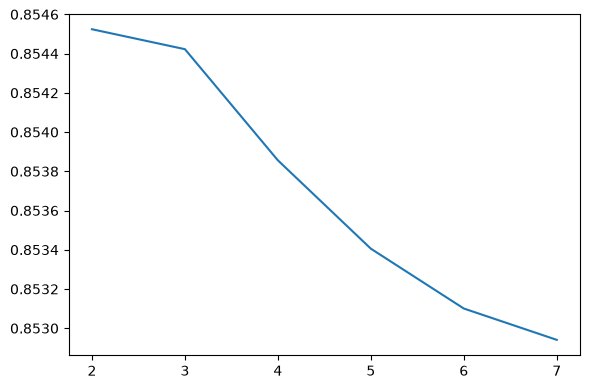

In [56]:
import matplotlib.pyplot as plt

K = range(2, 8)
fits = []
score = []

from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score

for k in K:
    model = XGBClassifier(
        n_estimators=k * 50,
        max_depth=6,
        learning_rate=0.1,
        random_state=42,
        eval_metric="logloss"
    )

    model.fit(X_train, y_train)
    fits.append(model)

    y_pred = model.predict(X_test)
    score.append(accuracy_score(y_test, y_pred))

plt.figure(figsize=(6, 4))
plt.plot(K, score)
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [58]:
import joblib

joblib.dump(model_fit, "model_diabetes_xgboost.pkl")

print("Model berhasil disimpan!")

Model berhasil disimpan!
